# Emotion Classification with Classical ML Models

**Goal:** predict one of six emotions (anger, fear, joy, love, sadness, surprise) from a short English sentence. This is the core of VoxAid: the user speaks, the speech is turned into text, and a classifier decides which emotion the text expresses.

**What this notebook does**
1. Loads the Phase 1 outputs (cleaned text, labels, TF-IDF features).
2. Trains **five models**: a baseline Logistic Regression (no class weights, as in the first version) and four tuned models: Multinomial Naive Bayes, Logistic Regression, Linear SVM and Random Forest.
3. Tunes hyperparameters with **5-fold stratified cross-validation** (3-fold for Random Forest because it is slow), scoring on **macro-F1**.
4. Evaluates every model on the held-out **test set** (2,000 rows) with accuracy, macro and weighted precision/recall/F1, ROC-AUC, top-3 accuracy and confusion matrices.
5. Looks at feature importance and the errors of the best model.
6. **Saves the trained models** to `../models/ml/` so the web app can use them.

## Imports

In [1]:
import json
import os
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import sklearn
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             top_k_accuracy_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

DATA_DIR = "../data/processed"
MODEL_DIR = "../models/ml"
PLOT_DIR = "../plots/ml"
RESULTS_DIR = "../results"
for d in (MODEL_DIR, PLOT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

SEED = 42
print("scikit-learn", sklearn.__version__)

scikit-learn 1.7.2


## Load datasets
The data comes from **Phase 1** (the DS project). Phase 1 cleaned the CARER emotion dataset and saved every split as two files in `../data/processed/`:

| File | What it contains | Used here for |
|---|---|---|
| `train_clean.csv`, `val_clean.csv`, `test_clean.csv` | cleaned text, label, `is_length_outlier` flag | original cleaned text |
| `train_processed.csv`, `val_processed.csv`, `test_processed.csv` | the cleaned columns plus `text_ml` (lower case, stop words removed, negations kept), `label_id` and scaled numeric features | text and labels for the ML models |

Rows after cleaning: **15,923 train / 1,993 val / 2,000 test** (duplicates, conflicting labels and train/val/test overlap were removed in Phase 1).

The ML models use the **processed** files.

In [2]:
train_df = pd.read_csv(f"{DATA_DIR}/train_processed.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val_processed.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test_processed.csv")

with open(f"{DATA_DIR}/label_mapping.json") as f:
    label_map = json.load(f)
CLASSES = sorted(label_map["label2id"], key=label_map["label2id"].get)

print(f"Train: {train_df.shape}, Val: {val_df.shape}, Test: {test_df.shape}")
print("Classes:", CLASSES)
train_df[["text", "text_ml", "label"]].head()

Train: (15923, 15), Val: (1993, 15), Test: (2000, 15)
Classes: ['anger', 'fear', 'joy', 'love', 'sadness', 'surprise']


,text,text_ml,label
0,i didnt feel humiliated,didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,feeling hopeless damned hopeful just cares awake,sadness
2,im grabbing a minute to post i feel greedy wrong,im grabbing minute post feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,feeling nostalgic fireplace know property,love
4,i am feeling grouchy,feeling grouchy,anger


### Class balance
The classes are imbalanced: *joy* and *sadness* make up about 63% of the data, while *surprise* is only about 3.5%. Phase 1 recommended **class weights** during training and **macro-F1** as the main metric, because accuracy and weighted F1 are dominated by the big classes and hide poor performance on *surprise* and *love*.

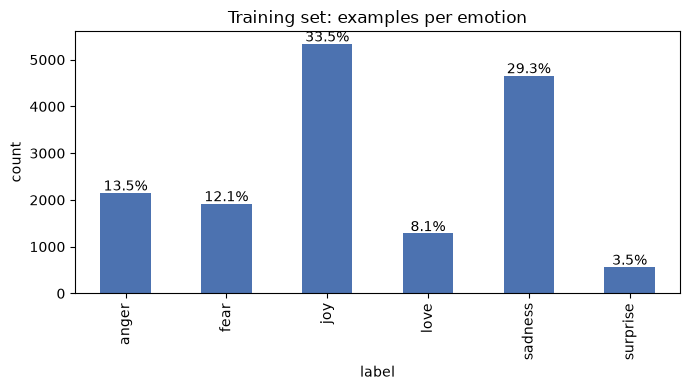

In [3]:
counts = train_df["label"].value_counts().reindex(CLASSES)
ax = counts.plot(kind="bar", color="#4C72B0", figsize=(7, 4))
ax.set_title("Training set: examples per emotion")
ax.set_ylabel("count")
for i, v in enumerate(counts):
    ax.text(i, v + 50, f"{v / counts.sum():.1%}", ha="center")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/class_distribution.png", dpi=150)
plt.show()

## Text vectorization
Phase 1 already built the TF-IDF features from the `text_ml` column (5,000 features, unigrams + bigrams, sublinear TF). The vectorizer was fitted on the **train split only** and then applied to val and test, so there is no data leakage. We load these matrices (`tfidf_*.npz`) instead of fitting a new vectorizer. The fitted vectorizer (`tfidf_vectorizer.joblib`) is loaded too, because it is saved together with each model so the app can turn new text into the same features.

In [4]:
tfidf_train = sp.load_npz(f"{DATA_DIR}/tfidf_train.npz")
tfidf_val = sp.load_npz(f"{DATA_DIR}/tfidf_val.npz")
tfidf_test = sp.load_npz(f"{DATA_DIR}/tfidf_test.npz")
vectorizer = joblib.load(f"{DATA_DIR}/tfidf_vectorizer.joblib")

assert tfidf_train.shape[0] == len(train_df)
assert tfidf_val.shape[0] == len(val_df)
assert tfidf_test.shape[0] == len(test_df)
# the saved vectorizer must reproduce the saved matrices
assert np.allclose(vectorizer.transform(test_df["text_ml"]).toarray(), tfidf_test.toarray())

print(f"TF-IDF Train: {tfidf_train.shape}, Val: {tfidf_val.shape}, Test: {tfidf_test.shape}")

TF-IDF Train: (15923, 5000), Val: (1993, 5000), Test: (2000, 5000)


## Train / test setup
Train and validation are combined (17,916 rows) for training. Instead of a single validation split, hyperparameters are chosen with **stratified k-fold cross-validation** on this combined set, which uses all the data and gives a more stable estimate. The **test set is never touched** until the final evaluation.

In [5]:
X_train = sp.vstack([tfidf_train, tfidf_val]).tocsr()
y_train = pd.concat([train_df["label"], val_df["label"]], ignore_index=True)
X_test = tfidf_test
y_test = test_df["label"]
print(f"Combined Train: {X_train.shape}, Test: {X_test.shape}")

Combined Train: (17916, 5000), Test: (2000, 5000)


## Models
| Model | Why it is a good fit | Class imbalance handling | Tuned hyperparameters |
|---|---|---|---|
| Logistic Regression (baseline) | the model from the first version, kept for comparison | none | none |
| Multinomial Naive Bayes | classic, very fast text baseline | `fit_prior=False` option (uniform priors) | `alpha`, `fit_prior` |
| Logistic Regression | linear model, strong on sparse TF-IDF, gives probabilities | `class_weight="balanced"` | `C` |
| Linear SVM (calibrated) | often the strongest linear text classifier; wrapped in `CalibratedClassifierCV` to get probabilities | `class_weight="balanced"` | `C` |
| Random Forest | non-linear, captures word interactions | `class_weight="balanced_subsample"` | `min_samples_leaf`, `max_features` |

In [6]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

experiments = {
    "Naive Bayes": (MultinomialNB(),
                    {"alpha": [0.03, 0.1, 0.3, 1.0], "fit_prior": [True, False]}, cv5),
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
                            {"C": [1, 3, 10, 30]}, cv5),
    # LinearSVC has no probabilities; calibration (5 internal folds) adds them, which the app needs for its confidence
    "Linear SVM": (CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=SEED), cv=5),
                   {"estimator__C": [0.1, 0.3, 1, 3]}, cv5),
    "Random Forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                             n_jobs=-1, random_state=SEED),
                      {"min_samples_leaf": [1, 2], "max_features": ["sqrt", 0.05]}, cv3),
}

### Baseline: Logistic Regression without class weights (first version)

In [7]:
models, cv_results, train_times = {}, {}, {}

t0 = time.time()
models["LR baseline (no weights)"] = LogisticRegression(max_iter=200, random_state=SEED).fit(X_train, y_train)
train_times["LR baseline (no weights)"] = time.time() - t0
print(f"trained in {train_times['LR baseline (no weights)']:.1f}s")

trained in 1.8s


### Hyperparameter tuning with cross-validation

In [8]:
for name, (estimator, grid, cv) in experiments.items():
    t0 = time.time()
    search = GridSearchCV(estimator, grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    train_times[name] = time.time() - t0
    models[name] = search.best_estimator_
    cv_results[name] = pd.DataFrame(search.cv_results_)[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ].sort_values("rank_test_score")
    print(f"{name:20s} best CV macro-F1 = {search.best_score_:.4f}  params = {search.best_params_}  "
          f"({train_times[name]:.0f}s)")

Naive Bayes          best CV macro-F1 = 0.8252  params = {'alpha': 1.0, 'fit_prior': False}  (15s)
Logistic Regression  best CV macro-F1 = 0.8783  params = {'C': 3}  (16s)
Linear SVM           best CV macro-F1 = 0.8836  params = {'estimator__C': 0.3}  (17s)
Random Forest        best CV macro-F1 = 0.8545  params = {'max_features': 'sqrt', 'min_samples_leaf': 1}  (68s)


Full cross-validation tables (mean ± std macro-F1 for every setting tried):

In [9]:
for name, table in cv_results.items():
    print(f"\n{name}")
    display(table.style.format({"mean_test_score": "{:.4f}", "std_test_score": "{:.4f}"}).hide(axis="index"))


Naive Bayes


params,mean_test_score,std_test_score,rank_test_score
"{'alpha': 1.0, 'fit_prior': False}",0.8252,0.0048,1
"{'alpha': 0.3, 'fit_prior': False}",0.8020,0.0057,2
"{'alpha': 0.1, 'fit_prior': False}",0.7893,0.0056,3
"{'alpha': 0.1, 'fit_prior': True}",0.7867,0.0134,4
"{'alpha': 0.3, 'fit_prior': True}",0.7784,0.0103,5
"{'alpha': 0.03, 'fit_prior': False}",0.7769,0.0050,6
"{'alpha': 0.03, 'fit_prior': True}",0.7689,0.0146,7
"{'alpha': 1.0, 'fit_prior': True}",0.6739,0.0111,8



Logistic Regression


params,mean_test_score,std_test_score,rank_test_score
{'C': 3},0.8783,0.0068,1
{'C': 10},0.8781,0.0060,2
{'C': 1},0.8757,0.0070,3
{'C': 30},0.8756,0.0081,4



Linear SVM


params,mean_test_score,std_test_score,rank_test_score
{'estimator__C': 0.3},0.8836,0.0052,1
{'estimator__C': 1},0.8805,0.0057,2
{'estimator__C': 0.1},0.8778,0.0070,3
{'estimator__C': 3},0.8723,0.0051,4



Random Forest


params,mean_test_score,std_test_score,rank_test_score
"{'max_features': 'sqrt', 'min_samples_leaf': 1}",0.8545,0.0052,1
"{'max_features': 0.05, 'min_samples_leaf': 1}",0.8499,0.0098,2
"{'max_features': 'sqrt', 'min_samples_leaf': 2}",0.8483,0.0071,3
"{'max_features': 0.05, 'min_samples_leaf': 2}",0.8483,0.0073,4


## Evaluation on the test set
For every model we report:
- **accuracy** and **macro-F1** (main metric: every emotion counts the same),
- macro precision / recall, and weighted F1 (to compare with the first version),
- **ROC-AUC** (one-vs-rest, macro) and **top-3 accuracy** where the model gives scores,
- the per-class report and a confusion matrix.

In [10]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def evaluate(model, name, X, y, save_plot=True):
    y_pred = model.predict(X)
    if hasattr(model, "predict_proba"):
        scores, is_proba = model.predict_proba(X), True
    else:  # LinearSVC has no probabilities, use decision scores
        scores, is_proba = model.decision_function(X), False
    classes = list(model.classes_)
    y_idx = np.array([classes.index(c) for c in y])

    m = {
        "accuracy": accuracy_score(y, y_pred),
        "macro_precision": precision_score(y, y_pred, average="macro"),
        "macro_recall": recall_score(y, y_pred, average="macro"),
        "macro_f1": f1_score(y, y_pred, average="macro"),
        "weighted_f1": f1_score(y, y_pred, average="weighted"),
        "roc_auc_ovr": roc_auc_score(y_idx, scores if is_proba else softmax(scores), multi_class="ovr", average="macro"),
        "top3_accuracy": top_k_accuracy_score(y_idx, scores, k=3, labels=range(len(classes))),
    }
    report = classification_report(y, y_pred, labels=CLASSES, output_dict=True)
    m["per_class_f1"] = {c: report[c]["f1-score"] for c in CLASSES}
    m["per_class_recall"] = {c: report[c]["recall"] for c in CLASSES}

    print(f"\n=== {name} ===")
    print("  ".join(f"{k}: {v:.3f}" for k, v in m.items() if not isinstance(v, dict)))
    print(classification_report(y, y_pred, labels=CLASSES, digits=3))

    cm = confusion_matrix(y, y_pred, labels=CLASSES)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
    axes[0].set_title(f"{name}: counts")
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES,
                ax=axes[1], vmin=0, vmax=1)
    axes[1].set_title(f"{name}: row-normalised (recall)")
    for ax in axes:
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.tight_layout()
    if save_plot:
        fname = name.replace(" ", "_").replace("(", "").replace(")", "")
        plt.savefig(f"{PLOT_DIR}/{fname}_confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    return m, y_pred


=== LR baseline (no weights) ===
accuracy: 0.895  macro_precision: 0.895  macro_recall: 0.807  macro_f1: 0.841  weighted_f1: 0.892  roc_auc_ovr: 0.992  top3_accuracy: 0.995
              precision    recall  f1-score   support

       anger      0.907     0.851     0.878       275
        fear      0.892     0.844     0.867       224
         joy      0.878     0.967     0.921       695
        love      0.879     0.686     0.770       159
     sadness      0.917     0.948     0.932       581
    surprise      0.900     0.545     0.679        66

    accuracy                          0.895      2000
   macro avg      0.895     0.807     0.841      2000
weighted avg      0.896     0.895     0.892      2000



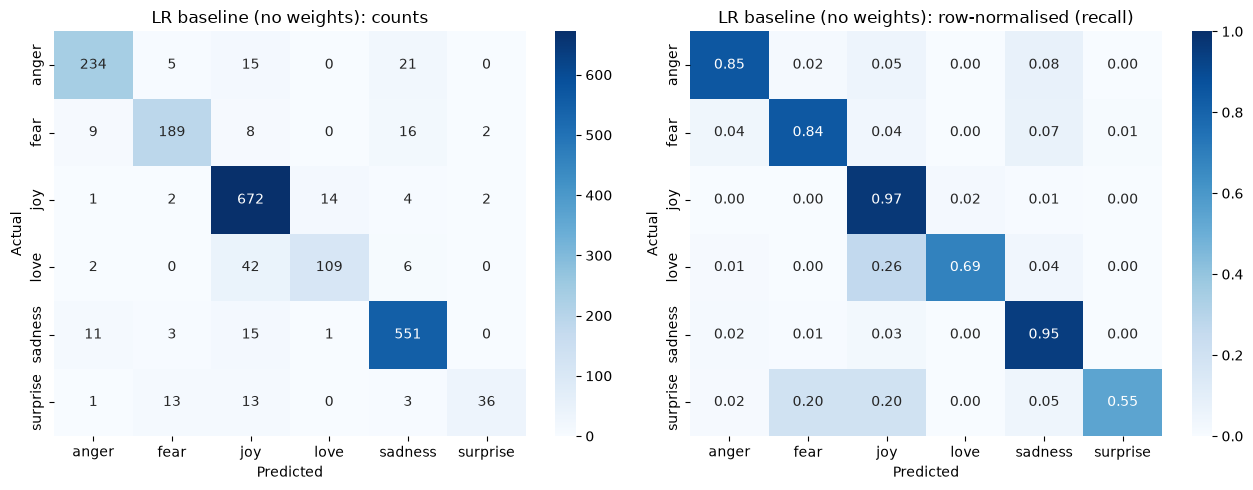


=== Naive Bayes ===
accuracy: 0.880  macro_precision: 0.820  macro_recall: 0.848  macro_f1: 0.832  weighted_f1: 0.882  roc_auc_ovr: 0.984  top3_accuracy: 0.989
              precision    recall  f1-score   support

       anger      0.870     0.898     0.884       275
        fear      0.857     0.853     0.855       224
         joy      0.919     0.885     0.902       695
        love      0.704     0.868     0.777       159
     sadness      0.942     0.902     0.922       581
    surprise      0.625     0.682     0.652        66

    accuracy                          0.880      2000
   macro avg      0.820     0.848     0.832      2000
weighted avg      0.885     0.880     0.882      2000



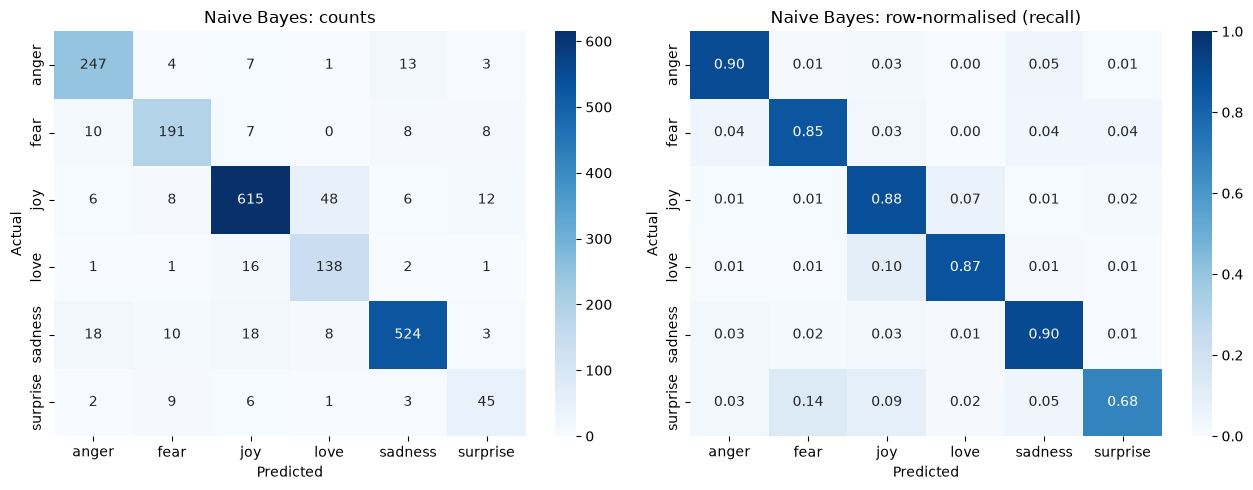


=== Logistic Regression ===
accuracy: 0.901  macro_precision: 0.843  macro_recall: 0.901  macro_f1: 0.866  weighted_f1: 0.903  roc_auc_ovr: 0.992  top3_accuracy: 0.996
              precision    recall  f1-score   support

       anger      0.882     0.927     0.904       275
        fear      0.892     0.848     0.870       224
         joy      0.951     0.894     0.921       695
        love      0.721     0.912     0.806       159
     sadness      0.962     0.914     0.937       581
    surprise      0.652     0.909     0.759        66

    accuracy                          0.901      2000
   macro avg      0.843     0.901     0.866      2000
weighted avg      0.910     0.901     0.903      2000



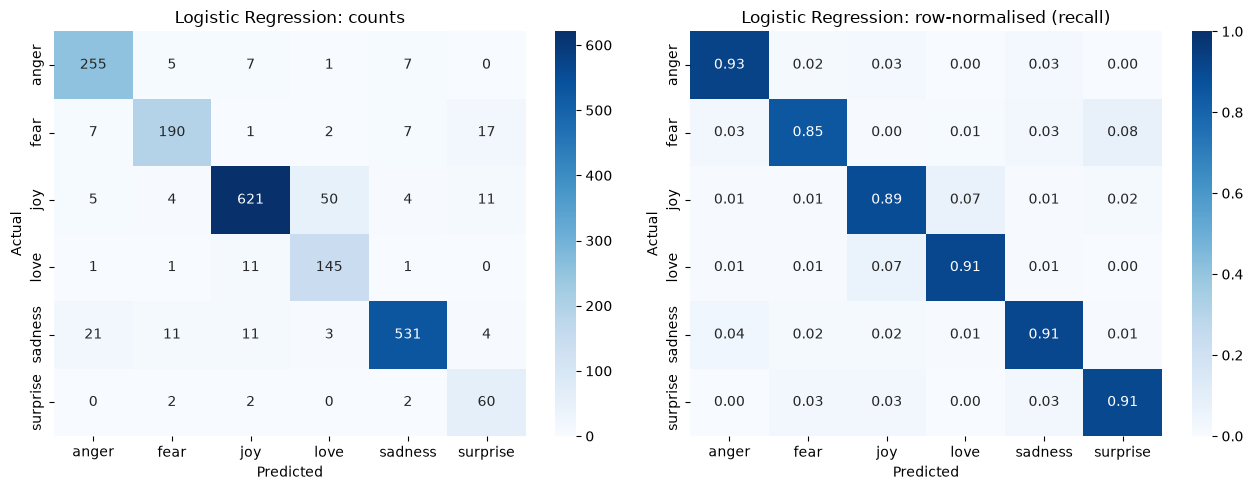


=== Linear SVM ===
accuracy: 0.910  macro_precision: 0.874  macro_recall: 0.862  macro_f1: 0.867  weighted_f1: 0.910  roc_auc_ovr: 0.994  top3_accuracy: 0.997
              precision    recall  f1-score   support

       anger      0.906     0.916     0.911       275
        fear      0.890     0.866     0.878       224
         joy      0.926     0.935     0.931       695
        love      0.789     0.849     0.818       159
     sadness      0.948     0.938     0.943       581
    surprise      0.786     0.667     0.721        66

    accuracy                          0.910      2000
   macro avg      0.874     0.862     0.867      2000
weighted avg      0.910     0.910     0.910      2000



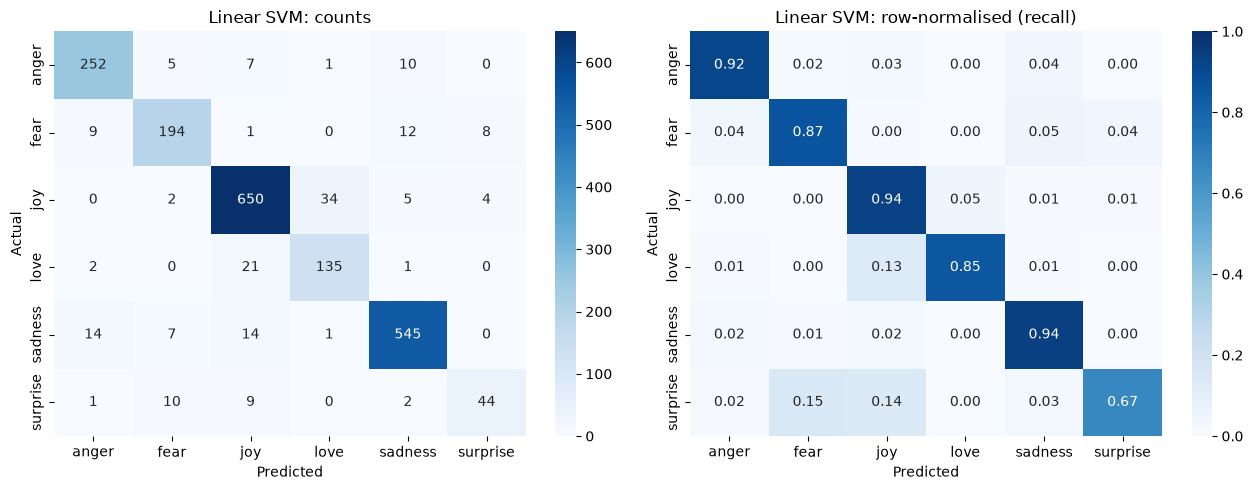


=== Random Forest ===
accuracy: 0.884  macro_precision: 0.830  macro_recall: 0.866  macro_f1: 0.846  weighted_f1: 0.886  roc_auc_ovr: 0.989  top3_accuracy: 0.996
              precision    recall  f1-score   support

       anger      0.889     0.902     0.895       275
        fear      0.856     0.902     0.878       224
         joy      0.903     0.899     0.901       695
        love      0.726     0.849     0.783       159
     sadness      0.960     0.873     0.914       581
    surprise      0.646     0.773     0.703        66

    accuracy                          0.884      2000
   macro avg      0.830     0.866     0.846      2000
weighted avg      0.890     0.884     0.886      2000



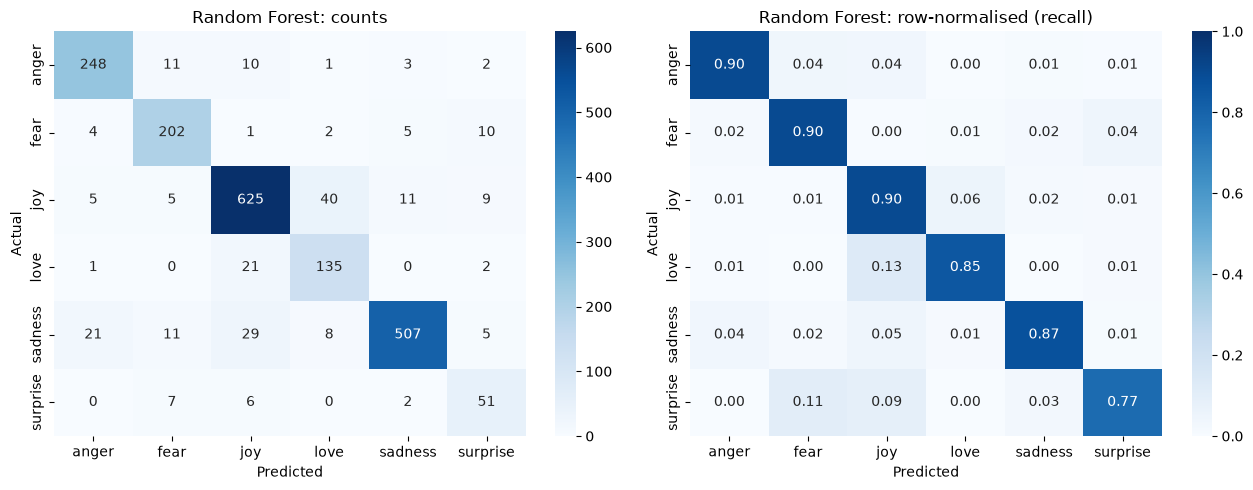

In [11]:
metrics, predictions = {}, {}
for name, model in models.items():
    metrics[name], predictions[name] = evaluate(model, name, X_test, y_test)
    metrics[name]["train_time_s"] = train_times[name]
    if name in cv_results:
        best = cv_results[name].iloc[0]
        metrics[name]["cv_macro_f1"] = float(best["mean_test_score"])
        metrics[name]["best_params"] = best["params"]

## Comparison table

In [12]:
cols = ["accuracy", "macro_f1", "macro_precision", "macro_recall", "weighted_f1", "roc_auc_ovr", "top3_accuracy", "train_time_s"]
summary = pd.DataFrame(metrics).T[cols].astype(float).sort_values("macro_f1", ascending=False)
display(summary.style.format("{:.3f}").format({"train_time_s": "{:.1f}"}).background_gradient(subset=["macro_f1"], cmap="Greens"))

,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,roc_auc_ovr,top3_accuracy,train_time_s
Linear SVM,0.910000,0.867031,0.874221,0.861908,0.909768,0.994279,0.996500,17.0
Logistic Regression,0.901000,0.866262,0.843482,0.900666,0.903301,0.991644,0.996000,15.5
Random Forest,0.884000,0.845865,0.829934,0.866217,0.885692,0.989125,0.996000,68.4
LR baseline (no weights),0.895500,0.841242,0.895459,0.806820,0.892217,0.992308,0.995000,1.8
Naive Bayes,0.880000,0.831905,0.819505,0.847898,0.881678,0.984342,0.989000,14.6


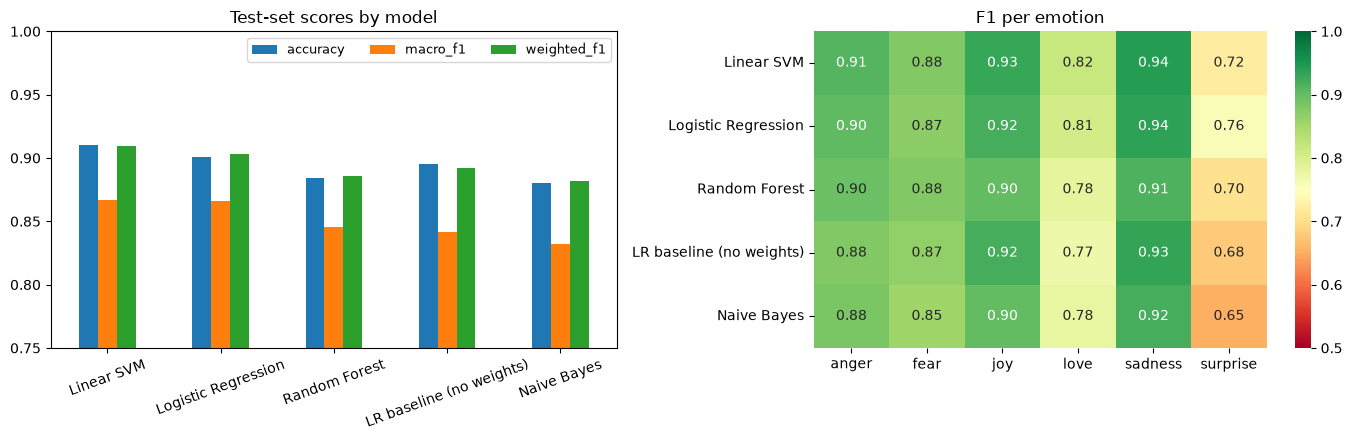

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
summary[["accuracy", "macro_f1", "weighted_f1"]].plot(kind="bar", ax=axes[0], ylim=(0.75, 1.0), rot=20)
axes[0].set_title("Test-set scores by model"); axes[0].legend(loc="upper right", ncol=3, fontsize=9)

per_class = pd.DataFrame({n: metrics[n]["per_class_f1"] for n in summary.index}).T
sns.heatmap(per_class, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.5, vmax=1, ax=axes[1])
axes[1].set_title("F1 per emotion")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/ml_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Effect of class weights
Comparing the baseline with the tuned, class-weighted Logistic Regression shows what Phase 1's recommendation does for the minority classes, especially the recall of *surprise* and *love*.

,baseline (no weights),tuned + class weights,change
anger,0.851,0.927,+0.076
fear,0.844,0.848,+0.004
joy,0.967,0.894,-0.073
love,0.686,0.912,+0.226
sadness,0.948,0.914,-0.034
surprise,0.545,0.909,+0.364


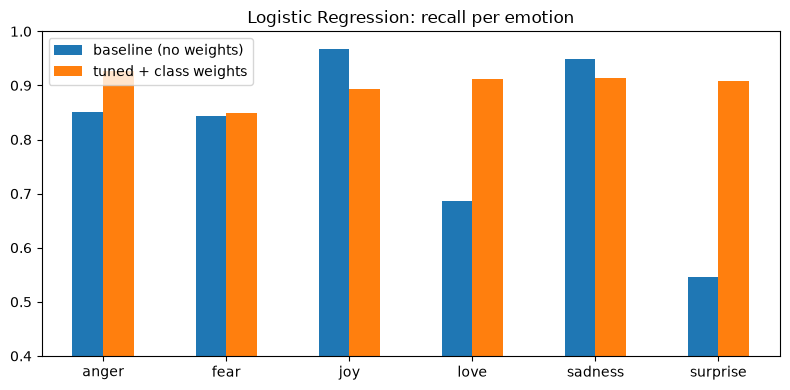

In [14]:
recall_cmp = pd.DataFrame({
    "baseline (no weights)": metrics["LR baseline (no weights)"]["per_class_recall"],
    "tuned + class weights": metrics["Logistic Regression"]["per_class_recall"],
})
recall_cmp["change"] = recall_cmp.iloc[:, 1] - recall_cmp.iloc[:, 0]
display(recall_cmp.style.format("{:+.3f}", subset=["change"]).format("{:.3f}", subset=recall_cmp.columns[:2]))

recall_cmp.iloc[:, :2].plot(kind="bar", figsize=(8, 4), rot=0, ylim=(0.4, 1.0), title="Logistic Regression: recall per emotion")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/class_weights_effect.png", dpi=150)
plt.show()

## Feature importance
For Logistic Regression each emotion has its own weight for every TF-IDF feature. The words with the largest positive weights are the strongest signals for that emotion.

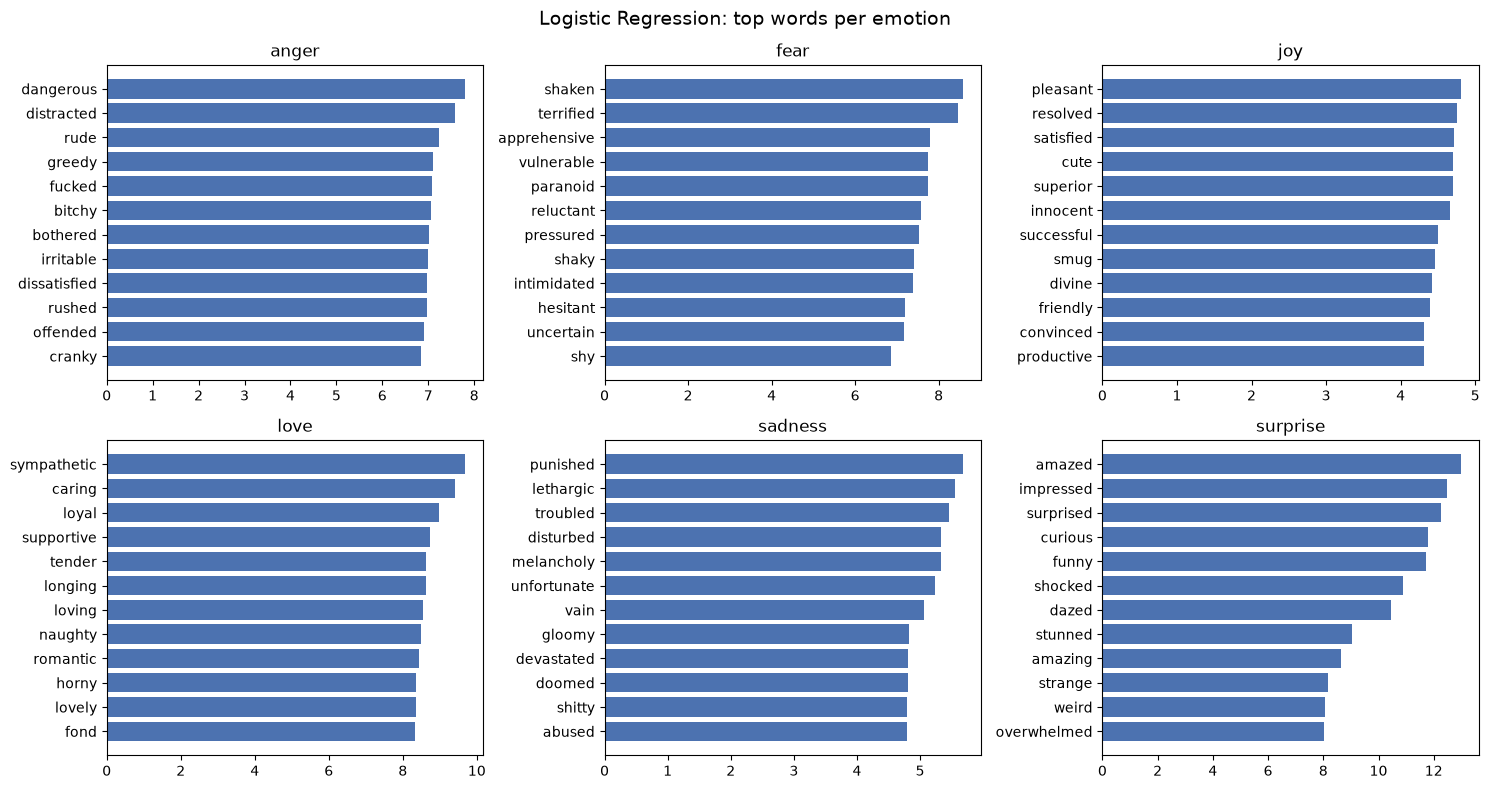

In [15]:
lr_tuned = models["Logistic Regression"]
feature_names = np.array(vectorizer.get_feature_names_out())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (i, cls) in zip(axes.ravel(), enumerate(lr_tuned.classes_)):
    top = np.argsort(lr_tuned.coef_[i])[-12:]
    ax.barh(feature_names[top], lr_tuned.coef_[i][top], color="#4C72B0")
    ax.set_title(cls)
plt.suptitle("Logistic Regression: top words per emotion", fontsize=14)
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/lr_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## Error analysis
Which emotions get confused with each other, and what do the mistakes look like?

In [16]:
best_name = summary.index[0]
print("Best model by macro-F1:", best_name)

err = test_df[["text", "label"]].copy()
err["predicted"] = predictions[best_name]
wrong = err[err["label"] != err["predicted"]]
print(f"{len(wrong)} of {len(err)} test sentences misclassified ({len(wrong) / len(err):.1%})\n")

pairs = wrong.groupby(["label", "predicted"]).size().sort_values(ascending=False).head(8)
print("Most common confusions (actual -> predicted):")
print(pairs.to_string())

Best model by macro-F1: Linear SVM
180 of 2000 test sentences misclassified (9.0%)

Most common confusions (actual -> predicted):
label     predicted
joy       love         34
love      joy          21
sadness   joy          14
          anger        14
fear      sadness      12
anger     sadness      10
surprise  fear         10
fear      anger         9


In [17]:
pd.set_option("display.max_colwidth", 120)
for (actual, pred) in pairs.index[:4]:
    print(f"\n--- actual: {actual}, predicted: {pred} ---")
    for t in wrong[(wrong.label == actual) & (wrong.predicted == pred)]["text"].head(3):
        print("  •", t)


--- actual: joy, predicted: love ---
  • i realized what i am passionate about helping women feel accepted and appreciated
  • i suppose if one was feeling generous one could say i was stressed by the elevator ride
  • i believe that people should choose the causes they feel passionate about and do what they can and i have no right or desire to push my own charities as more worthy than another

--- actual: love, predicted: joy ---
  • im feeling generous today heres one more you may have already seen but is good for a chuckle
  • i feel so blessed and honored that we get to be its parents
  • i was so impressed with the show especially for hs and i was moved by these talented kids but then again i feel very passionate about productions and music and theatre in schools so i am always happy to endorse many hs productions throughout their seasons during this time

--- actual: sadness, predicted: joy ---
  • i can t stop the anxiety i feel when i m alone when i ve got no distractions
  • 

**What the errors show**
- Most mistakes are between emotionally close pairs: *joy ↔ love*, *fear ↔ surprise*, *anger ↔ sadness*. Words like "amazed" or "overwhelmed" can mean either.
- CARER labels were created from hashtags, so some labels are noisy: a sentence such as "i feel strange" can carry either *fear* or *surprise*.
- A bag-of-words model cannot see word order or context, so negation and sarcasm ("i dont feel happy at all") are hard. The negations kept in Phase 1 help, but only partly; sequence models (LSTM, transformer) handle this better.

## Save models
Each model is saved as a scikit-learn `Pipeline` of **(Phase 1 TF-IDF vectorizer → classifier)**. The pipeline takes `text_ml` (cleaned text with stop words removed) and returns the emotion, so the web app needs only one file per model. The baseline is not saved because it is only for comparison.

The Random Forest file is about 75 MB, so it is listed in `.gitignore` and not pushed to GitHub; running this notebook recreates it. The app uses the small linear models (under 1 MB each).

In [18]:
SLUGS = {"Logistic Regression": "logistic_regression", "Linear SVM": "linear_svm",
         "Naive Bayes": "naive_bayes", "Random Forest": "random_forest"}

for name, slug in SLUGS.items():
    pipe = Pipeline([("tfidf", vectorizer), ("clf", models[name])])
    path = f"{MODEL_DIR}/{slug}.joblib"
    joblib.dump(pipe, path, compress=3)
    print(f"saved {path:45s} {os.path.getsize(path) / 1e6:6.1f} MB")

with open(f"{MODEL_DIR}/metadata.json", "w") as f:
    json.dump({"input": "text_ml (see app/voxaid_core.py: clean_text + to_ml_text)",
               "classes": CLASSES, "sklearn_version": sklearn.__version__,
               "models": SLUGS}, f, indent=2)

saved ../models/ml/logistic_regression.joblib          0.3 MB
saved ../models/ml/linear_svm.joblib                   1.2 MB
saved ../models/ml/naive_bayes.joblib                  0.4 MB
saved ../models/ml/random_forest.joblib               76.8 MB


In [19]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {k: to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o

with open(f"{RESULTS_DIR}/ml_metrics.json", "w") as f:
    json.dump(to_jsonable(metrics), f, indent=2)
print("Metrics saved to ../results/ml_metrics.json")

Metrics saved to ../results/ml_metrics.json


### Sanity check: the saved model on new sentences
The saved pipeline is loaded back and used with the same preprocessing function as the web app (`app/voxaid_core.py`).

In [20]:
sys.path.insert(0, "../app")
from voxaid_core import clean_text, to_ml_text

pipe = joblib.load(f"{MODEL_DIR}/logistic_regression.joblib")
samples = ["I can't believe I finally got the job, I'm so happy!",
           "I'm really worried about my exam tomorrow",
           "Why does everyone keep ignoring me, it's so annoying",
           "I miss my grandmother so much",
           "Wow, I did not expect that at all!",
           "I feel so lucky to have you in my life"]
for s in samples:
    proba = pipe.predict_proba([to_ml_text(clean_text(s))])[0]
    top = np.argsort(proba)[::-1][:2]
    print(f"{s:55s} -> {pipe.classes_[top[0]]:8s} ({proba[top[0]]:.2f}), then {pipe.classes_[top[1]]} ({proba[top[1]]:.2f})")

I can't believe I finally got the job, I'm so happy!    -> joy      (0.46), then sadness (0.20)
I'm really worried about my exam tomorrow               -> fear     (0.47), then sadness (0.17)
Why does everyone keep ignoring me, it's so annoying    -> sadness  (0.35), then joy (0.28)
I miss my grandmother so much                           -> sadness  (0.39), then joy (0.18)
Wow, I did not expect that at all!                      -> joy      (0.32), then fear (0.20)
I feel so lucky to have you in my life                  -> joy      (0.96), then sadness (0.02)


## Conclusion
- The table above gives the final numbers. Linear models (Linear SVM and Logistic Regression) work best on TF-IDF features: they are accurate, train in seconds and give the app instant predictions. Random Forest is slower, much larger on disk and does not beat them on sparse text features. Naive Bayes is the weakest but fastest.
- Linear SVM and Logistic Regression are practically tied on macro-F1. Calibrating the SVM (needed so the app gets real probabilities) pulls its predictions back toward the class frequencies, so it has the highest accuracy and precision, while the class-weighted Logistic Regression has the best recall on the rare emotions (surprise recall about 0.91).
- **Class weights** trade a little accuracy on the big classes for clearly better recall on *surprise* and *love*, which raises macro-F1, the metric that treats every emotion as equally important.
- Remaining errors come from emotionally close classes, noisy hashtag labels, and the lack of word order in bag-of-words features. The deep learning notebook (`classification_DL.ipynb`) and transformer notebook (`transformer.ipynb`) test sequence models that can use context.